# 03 · Answers: are they correct, and are they grounded in the sources?

Retrieval finding the right passage is necessary, not sufficient. This notebook looks at the answers
Qwen3-4B-Instruct writes from the retrieved chunks, produced by `scripts/evaluate_generation.py` for all 110
questions under four setups:

| setup | what the LLM sees |
|---|---|
| `closed_book` | nothing, just the question (what the model knows on its own) |
| `bm25` | top 5 chunks from BM25 |
| `dense` | top 5 chunks from bge-m3 + FAISS |
| `hybrid_rerank` | top 5 after RRF fusion and the cross-encoder (what the API serves) |

**Four questions about each answer:**

- **Correct?** Compared with the hand-written reference answer by an LLM judge: CORRECT / PARTIAL / INCORRECT.
- **Faithful?** Each sentence of the answer is a *claim*. A claim is faithful if the retrieved chunks support it.
  Faithfulness = share of faithful claims. This is the "is it making things up?" metric, and it is
  different from correctness: an answer can be correct but unfaithful (it came from the model's memory,
  not the sources), or faithful but wrong (the sources were the wrong ones).
- **Citations right?** Citation precision = share of cited claims that the cited chunk(s) on their own support.
- **Did it abstain?** The model is told to answer with one fixed sentence when the sources don't contain the answer.

In [1]:
import sys
sys.path.insert(0, "../src")

import ast
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from course_rag import plots
from course_rag.config import FIGURES_DIR, GENERATION_DIR, METRICS_DIR
from course_rag.evaluation import bootstrap_ci, extract_claims, load_questions

plots.setup()
pd.set_option("display.max_colwidth", 200)
df = pd.read_csv(GENERATION_DIR / "answers_scored.csv")
for col in ["cited", "nli_claim_scores", "llm_claim_scores"]:
    df[col] = df[col].apply(lambda v: ast.literal_eval(v) if isinstance(v, str) else [])
summary = json.loads((METRICS_DIR / "generation.json").read_text(encoding="utf-8"))
questions = {q.qid: q for q in load_questions()}
CONFIGS = {"closed_book": "Closed book (no retrieval)", "bm25": "BM25", "dense": "Dense", "hybrid_rerank": "Hybrid + reranker"}

rows = []
for c, name in CONFIGS.items():
    s = summary[c]["overall"]
    rows.append({"setup": name, "correct": s["correct"], "correct or partial": s["correct_or_partial"],
                 "said 'not found' on answerable": s["false_abstention"],
                 "said 'not found' on unanswerable": s["abstention_on_unanswerable"],
                 "faithfulness (LLM judge)": s.get("llm_faithfulness"), "faithfulness (NLI)": s.get("nli_faithfulness"),
                 "citation precision (LLM judge)": s.get("llm_citation_precision"),
                 "answers with citations": s.get("answers_with_citations")})
table = pd.DataFrame(rows).set_index("setup")
table.round(3)

,correct,correct or partial,said 'not found' on answerable,said 'not found' on unanswerable,faithfulness (LLM judge),faithfulness (NLI),citation precision (LLM judge),answers with citations
setup,,,,,,,,
Closed book (no retrieval),0.765,0.969,0.020,0.000,NaN,NaN,NaN,NaN
BM25,0.663,0.684,0.296,0.833,0.913,0.827,0.936,0.986
Dense,0.898,0.980,0.020,1.000,0.939,0.889,0.931,1.000
Hybrid + reranker,0.918,0.959,0.031,1.000,0.960,0.848,0.949,0.989


In one sentence: **with hybrid retrieval and the reranker, 92% of answers are correct, about 96% of their
claims are supported by the cited course text, and the assistant refused all 12 questions the course
doesn't cover. Without retrieval, the same model answered all 12 anyway.**

The rest of the notebook checks where those numbers come from, and how far to trust them.

## Correctness

In [2]:
answerable = df[df.kind != "unanswerable"].copy()
answerable["correct"] = (answerable.correctness == "CORRECT").astype(float)
for c in CONFIGS:
    g = answerable[answerable.config == c]
    lo, hi = bootstrap_ci(g.correct)
    print(f"{CONFIGS[c]:28s} correct {g.correct.mean():.3f}  (95% CI {lo:.3f}–{hi:.3f})   "
          f"same-lang {g[g.kind == 'same-language'].correct.mean():.3f}   cross-lang {g[g.kind == 'cross-language'].correct.mean():.3f}")

Closed book (no retrieval)   correct 0.765  (95% CI 0.683–0.847)   same-lang 0.805   cross-lang 0.737
BM25                         correct 0.663  (95% CI 0.571–0.755)   same-lang 1.000   cross-lang 0.421
Dense                        correct 0.898  (95% CI 0.837–0.949)   same-lang 0.951   cross-lang 0.860
Hybrid + reranker            correct 0.918  (95% CI 0.857–0.969)   same-lang 0.951   cross-lang 0.895


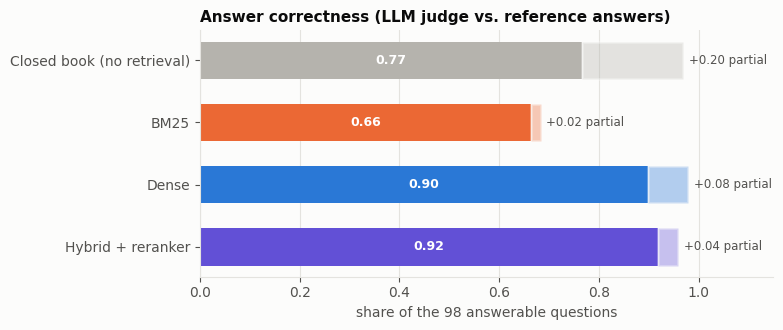

In [3]:
fig, ax = plt.subplots(figsize=(7.4, 3.2))
names = list(CONFIGS.values())
y = np.arange(len(names))
correct = [summary[c]["overall"]["correct"] for c in CONFIGS]
partial = [summary[c]["overall"]["correct_or_partial"] - summary[c]["overall"]["correct"] for c in CONFIGS]
colors = [plots.MUTED, plots.SERIES[1], plots.SERIES[0], plots.SERIES[6]]
b1 = ax.barh(y, correct, height=0.6, color=colors, label="correct")
ax.barh(y, partial, left=correct, height=0.6, color=colors, alpha=0.35, label="partially correct",
        edgecolor=plots.SURFACE, linewidth=2)
for yi, c, p in zip(y, correct, partial):
    ax.annotate(f"{c:.2f}", (c / 2, yi), ha="center", va="center", fontsize=9, color="white", weight="bold")
    ax.annotate(f"+{p:.2f} partial", (c + p, yi), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8.5, color=plots.TEXT_2)
ax.set_yticks(y, names); ax.invert_yaxis(); ax.set_xlim(0, 1.15); ax.grid(axis="y", visible=False)
ax.set_xlabel("share of the 98 answerable questions")
ax.set_title("Answer correctness (LLM judge vs. reference answers)")
fig.savefig(FIGURES_DIR / "answer_correctness.png")
plt.show()

**The closed-book baseline is strong, and that's worth saying plainly.** The corpus is Wikipedia, which Qwen
saw in pretraining, so even with no retrieval it gets 77% fully right and almost everything else partly
right. With a real lecturer's notes the gap would be bigger. Even so, retrieval adds 15 points (0.77 → 0.92),
and most of that comes from turning PARTIAL answers into CORRECT ones (see the crosstab below): the
course-specific detail, like *which* scheduler Unix uses by default *according to this course*, is
exactly what the model doesn't remember.

**BM25 is the worst setup, worse than no retrieval at all.** Not because it makes things up: when it
retrieves the wrong text (common for cross-language questions, where its recall is 0.30), the model
correctly says "not found" (30% of answerable questions). That's grounded behaviour, but it isn't helpful.

### Does a better retrieval give better answers?

In [4]:
rag = answerable[answerable.config != "closed_book"]
pd.crosstab([rag.config, rag["retrieval_hit@5"].map({True: "relevant chunk in top 5", False: "no relevant chunk"})],
            rag.correctness, normalize="index").round(2)

correctness                            CORRECT  INCORRECT  PARTIAL
config        retrieval_hit@5                                     
bm25          no relevant chunk           0.27       0.69     0.04
              relevant chunk in top 5     1.00       0.00     0.00
dense         no relevant chunk           0.17       0.33     0.50
              relevant chunk in top 5     0.95       0.00     0.05
hybrid_rerank no relevant chunk           0.00       1.00     0.00
              relevant chunk in top 5     0.95       0.01     0.04

In [5]:
cb = answerable[answerable.config == "closed_book"].set_index("qid").correctness
hr = answerable[answerable.config == "hybrid_rerank"].set_index("qid").correctness
pd.crosstab(cb.rename("closed book"), hr.rename("hybrid + reranker"))

hybrid + reranker,CORRECT,INCORRECT,PARTIAL
closed book,,,
CORRECT,69,3,3
INCORRECT,3,0,0
PARTIAL,18,1,1


- **When a relevant chunk is in the top 5, the answer is correct 95–100% of the time**, whatever the retriever.
  The LLM is not the bottleneck; retrieval is.
- **When retrieval misses, hybrid + reranker says "not found" every time** (its 3 misses) instead of guessing.
  Dense guesses more on its misses: half its answers there are partly right, from neighbouring chunks or memory.
- Compared question by question with the closed-book model: 18 partial answers become correct with retrieval;
  3 questions the model knew go to "not found", because retrieval missed the passage (q011, q018, q030 from notebook 02).
  That's the trade a grounded assistant makes on purpose: it would rather say "not in the course" than answer
  from memory without a source to cite.

## Faithfulness: two judges, and why both

In [6]:
answered = df[(df.config != "closed_book") & ~df.abstained & df.nli_faithfulness.notna()].copy()
claims = []
for r in answered.itertuples():
    for i, (n, l) in enumerate(zip(r.nli_claim_scores, r.llm_claim_scores)):
        claims.append({"config": r.config, "qid": r.qid, "kind": r.kind, "q_lang": r.q_lang, "doc_lang": r.doc_lang,
                       "claim": extract_claims(r.answer)[i][0], "nli": n, "llm": l})
claims = pd.DataFrame(claims)
claims["nli_ok"], claims["llm_ok"] = claims.nli >= 0.5, claims.llm >= 0.5
print(f"{len(claims)} claims in {len(answered)} answers")
agree = (claims.nli_ok == claims.llm_ok).mean()
print(f"the two judges agree on {agree:.1%} of claims\n")
claims.groupby(["kind"])[["nli_ok", "llm_ok"]].mean().round(3).rename(columns={"nli_ok": "supported (NLI)", "llm_ok": "supported (LLM)"})

498 claims in 260 answers
the two judges agree on 83.5% of claims



,supported (NLI),supported (LLM)
kind,,
cross-language,0.790,0.923
same-language,0.892,0.960


In [7]:
pd.crosstab(claims.nli_ok.map({True: "NLI: supported", False: "NLI: not supported"}),
            claims.llm_ok.map({True: "LLM: supported", False: "LLM: not supported"}))

llm_ok,LLM: not supported,LLM: supported
nli_ok,,
NLI: not supported,13,66
NLI: supported,16,403


In [8]:
print("NLI says no, LLM says yes (cross-language):\n")
for r in claims[~claims.nli_ok & claims.llm_ok & (claims.kind == "cross-language")].head(4).itertuples():
    print(f"  {r.qid} ({r.q_lang}←{r.doc_lang})  nli {r.nli:.2f}  llm {r.llm:.2f}  {r.claim[:160]}")
print("\nBoth say no:\n")
for r in claims[~claims.nli_ok & ~claims.llm_ok & (claims.config == "hybrid_rerank")].head(6).itertuples():
    print(f"  {r.qid} ({r.q_lang}←{r.doc_lang})  nli {r.nli:.2f}  llm {r.llm:.2f}  {r.claim[:160]}")

NLI says no, LLM says yes (cross-language):

  q004 (fr←ar)  nli 0.21  llm 1.00  La couche du modèle OSI responsable de l'acheminement des données à travers le réseau est la couche 3, la couche réseau.
  q010 (en←ar)  nli 0.21  llm 1.00  No, the Internet Protocol (IP) does not guarantee that packets are delivered; it only handles the addressing and routing of packets across networks, and does no
  q032 (en←fr)  nli 0.14  llm 1.00  Bill Gates bought QDOS, a quick-and-dirty operating system for processors, so he could supply IBM's PC.
  q040 (en←fr)  nli 0.01  llm 1.00  The four necessary conditions for deadlock are called the "conditions of Coffman," and they were first described in 1971.

Both say no:

  q008 (fr←ar)  nli 0.09  llm 0.00  Le champ « taille de la fenêtre » indique le nombre d'octets que le destinataire peut recevoir sans avoir à demander de confirmation, ce qui permet de gérer le 
  q022 (en←ar)  nli 0.39  llm 0.00  These libraries offer standardized, efficient implement

**The judges agree on 84% of claims, and they disagree in one direction.** When they differ, it's almost always
the NLI model saying "not supported" while the LLM says "supported" (66 of 82 disagreements), and it happens much
more on cross-language answers: NLI accepts 79% of cross-language claims against 89% of same-language ones.
The examples show why. "The four conditions … were first described in 1971", checked against the French
passage "*conditions de Coffman … un article de 1971*", gets 0.01 entailment from NLI. That's plainly a
false negative. The multilingual NLI model was trained mostly on same-language pairs, and it under-scores
paraphrases across languages.

The LLM judge has the opposite risk: it's the model that wrote the answers. So I report both. The true
faithfulness of hybrid + reranker is somewhere between **0.85 (NLI, a lower bound)** and **0.96 (LLM)**, and from
reading the disagreements, closer to the LLM number.

When **both** judges reject a claim, it's usually a real problem, though rarely an invented fact. It's typically an
*embellishment*: q008 adds "to avoid data loss" to an otherwise correct definition, and q036 generalises "only
FIFO is affected", which the passage doesn't say. The one answer judged INCORRECT despite good retrieval (q001,
in the failures below) mixes in a sentence from a neighbouring chunk about a different network type. These
are the cases a stricter prompt, or a claim-level check before answering, would target.

## Abstaining: "it's not in the course"

In [9]:
hr_all = df[df.config == "hybrid_rerank"]
for kind in ["same-language", "cross-language", "unanswerable"]:
    g = hr_all[hr_all.kind == kind]
    print(f"{kind:15s} n={len(g):3d}  said 'not found': {g.abstained.mean():.2f}")

same-language   n= 41  said 'not found': 0.00
cross-language  n= 57  said 'not found': 0.05
unanswerable    n= 12  said 'not found': 1.00


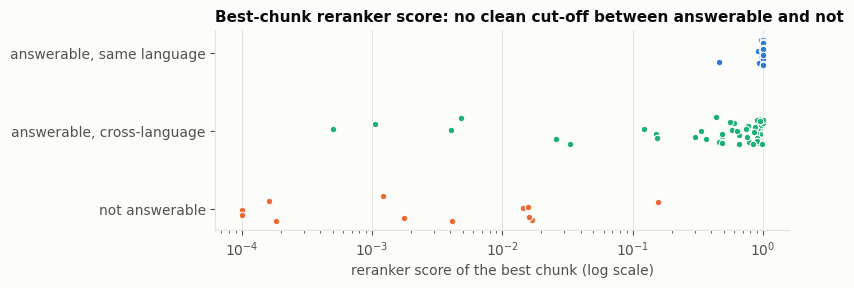

In [10]:
fig, ax = plt.subplots(figsize=(7.4, 2.6))
groups = [("answerable, same language", hr_all[hr_all.kind == "same-language"], plots.SERIES[0]),
          ("answerable, cross-language", hr_all[hr_all.kind == "cross-language"], plots.SERIES[2]),
          ("not answerable", hr_all[hr_all.kind == "unanswerable"], plots.SERIES[1])]
rng = np.random.default_rng(0)
for i, (name, g, color) in enumerate(groups):
    s = g.top_rerank_score.clip(lower=1e-4)
    ax.scatter(s, i + rng.uniform(-0.18, 0.18, len(s)), s=22, color=color, edgecolor=plots.SURFACE, linewidth=0.8, zorder=3)
ax.set_xscale("log"); ax.set_yticks(range(3), [g[0] for g in groups]); ax.invert_yaxis()
ax.set_xlabel("reranker score of the best chunk (log scale)")
ax.set_title("Best-chunk reranker score: no clean cut-off between answerable and not")
ax.grid(axis="y", visible=False)
fig.savefig(FIGURES_DIR / "abstention_scores.png")
plt.show()

In [11]:
for t in [0.005, 0.01, 0.02, 0.05, 0.1, 0.2]:
    ans, un = hr_all[hr_all.kind != "unanswerable"], hr_all[hr_all.kind == "unanswerable"]
    gate = lambda g: (g.top_rerank_score < t) | g.abstained
    print(f"threshold {t:<6} answerable wrongly refused {gate(ans).mean():.3f}   unanswerable refused {gate(un).mean():.3f}")

threshold 0.005  answerable wrongly refused 0.051   unanswerable refused 1.000
threshold 0.01   answerable wrongly refused 0.051   unanswerable refused 1.000
threshold 0.02   answerable wrongly refused 0.051   unanswerable refused 1.000
threshold 0.05   answerable wrongly refused 0.071   unanswerable refused 1.000
threshold 0.1    answerable wrongly refused 0.071   unanswerable refused 1.000
threshold 0.2    answerable wrongly refused 0.092   unanswerable refused 1.000


The model's own "not found" works: 0% on same-language answerable questions, 5% on cross-language ones (exactly
the 3 retrieval misses), and 100% on the 12 that the course doesn't cover.

I had also planned a cheaper shortcut: skip the LLM when the reranker's best score is low. The plot shows why it
doesn't work here. Cross-language pairs get low reranker scores even when the passage is right: q062 (an Arabic question
answered correctly from the French SQL course) has a best score of 0.0005, lower than most off-topic questions. Every
threshold in the sweep refuses extra answerable questions and catches nothing the LLM didn't already catch.
So the shortcut is **off by default** (`COURSE_RAG_MIN_SCORE` can still turn it on).

## Examples

In [12]:
def show(qid, config="hybrid_rerank"):
    r = df[(df.config == config) & (df.qid == qid)].iloc[0]
    q = questions[qid]
    print(f"[{qid} · {q.q_lang} question, answer in {q.doc_lang or '—'} · {r.correctness}]  {q.question}\n")
    print(r.answer, "\n")
    print("retrieved:", r.retrieved, "\n" + "-" * 100)

for qid in ["q008", "q035", "q090", "q105"]:
    show(qid)

[q008 · fr question, answer in ar · CORRECT]  À quoi sert le champ « taille de la fenêtre » dans l'en-tête TCP ?

Le champ « taille de la fenêtre » indique le nombre d'octets que le destinataire peut recevoir sans avoir à demander de confirmation, ce qui permet de gérer le débit et éviter les pertes de données [1]. Il détermine la taille de la fenêtre glissante utilisée par l'expéditeur [1]. 

retrieved: ar/tcp#003 ar/http#000 ar/tcp#000 ar/ip#000 ar/tcp#002 
----------------------------------------------------------------------------------------------------
[q035 · en question, answer in fr · CORRECT]  What is the default scheduling policy on Unix according to the course?

The default scheduling policy on Unix is "decay", which is an adaptive priority system that favors interactive tasks to ensure good response time [2]. 

retrieved: fr/systeme-exploitation#047 fr/ordonnancement#008 fr/ordonnancement#011 fr/systeme-exploitation#041 fr/systeme-exploitation#051 
------------------------

## Where hybrid + reranker gets it wrong

In [13]:
bad = df[(df.config == "hybrid_rerank") & (df.correctness == "INCORRECT")]
for _, r in bad.iterrows():
    q = questions[r.qid]
    print(f"{r.qid} ({q.q_lang}→{q.doc_lang})  relevant chunk retrieved: {r['retrieval_hit@5']}  {q.question}")
    print(f"   reference: {q.answer[:150]}")
    print(f"   answer:    {r.answer[:300]}\n")

q001 (ar→ar)  relevant chunk retrieved: True  ما هي الشبكة الشخصية PAN؟
   reference: شبكة تربط مجموعة أجهزة قريبة من المستخدم.
   answer:    الشبكة الشخصية PAN هي شبكة تربط مجموعة أجهزة قريبة من المستخدم، وتُستخدم عادةً لربط أجهزة مثل الهواتف أو الحواسيب أو الأجهزة الذكية في نطاق قريب [2]. تُستخدم هذه الشبكة لتبادل المعلومات والموارد بين الأجهزة القريبة من المستخدم [4]. تُعرف أيضًا باسم شبكة التخزين (SAN) في بعض السياقات، وهي شبكة متخصصة

q011 (fr→ar)  relevant chunk retrieved: False  Comment appelle-t-on l'opération qui ajoute les en-têtes à la charge utile d'un paquet IP ?
   reference: L'encapsulation.
   answer:    Je n'ai pas trouvé cette information dans les documents du cours.

q018 (fr→ar)  relevant chunk retrieved: False  Quelle est la limite d'un pare-feu sans état (stateless) ?
   reference: Il sait filtrer les paquets mais ne peut pas prendre de décisions complexes qui dépendent de l'état de la connexion entre les hôtes.
   answer:    Je n'ai pas trouvé cette information d

Four incorrect answers out of 98. Three are the retrieval misses from notebook 02, where the assistant correctly
said it couldn't find the answer. The fourth (q001) starts right and then mixes up two network types.

## How far to trust these numbers

- **98 answerable questions** is enough to separate big effects (retrieval vs none, BM25 vs dense), not small
  ones: dense vs hybrid + reranker (0.90 vs 0.92) is within noise.
- **Correctness and one of the faithfulness scores come from an LLM judge**, and it's the same model that wrote the
  answers. The NLI judge is independent but biased against cross-language claims. Neither has been calibrated
  against human labels on these answers. That's the next thing I'd do: hand-label ~50 answers and measure each
  judge's agreement with them.
- The questions and reference answers were written with an AI assistant. A script checks that every evidence quote
  exists in its document, and the labels were reviewed with AI help (102 of 110 marked verified). They were not
  independently labelled by several people, so treat them as careful but single-source.